# Ekstraksi Data Deret Waktu & Fitur Pertumbuhan (MoM & YoY) Industri Tembakau (2017–2025)

Notebook ini melakukan ekstraksi data mentah deret waktu (*time series*) dari folder `data_raw` untuk rentang waktu **2017 s/d 2025** (108 bulan observasi), sekaligus menambahkan fitur dinamika pertumbuhan:
1. **IPI MoM & YoY**: Laju pertumbuhan bulanan (*Month-on-Month*) dan tahunan (*Year-on-Year*) Indeks Produksi Industri Pengolahan Tembakau.
2. **Inflasi YoY**: Rekonstruksi laju inflasi tahunan (*Year-on-Year*) Subkelompok Tembakau dan Inflasi Umum Nasional berdasarkan laju bulanan M-to-M.

---

### Spesifikasi Variabel & Fitur

| No | Nama Kolom | Nama Variabel / Fitur | Sumber | Satuan / Skala | Deskripsi & Peran |
|---|---|---|---|---|---|
| 1 | `periode` | Tanggal Deret Waktu | Diturunkan | `YYYY-MM-01` | Indeks waktu bulanan awal bulan (*Month Start*) |
| 2 | `tahun` | Tahun Observasi | - | Integer | 2017 s/d 2025 |
| 3 | `bulan` | Bulan Observasi | - | Integer | 1 s/d 12 |
| 4 | `ipi_tembakau` | IPI Pengolahan Tembakau | BPS (KBLI 12) | Angka Indeks | Target prediksi utama ($Y_t$) |
| 5 | `ipi_mom` | Pertumbuhan MoM IPI | Diturunkan dari IPI | Persentase (%) | $\frac{IPI_t - IPI_{t-1}}{IPI_{t-1}} \times 100$ |
| 6 | `ipi_yoy` | Pertumbuhan YoY IPI | Diturunkan dari IPI | Persentase (%) | $\frac{IPI_t - IPI_{t-12}}{IPI_{t-12}} \times 100$ |
| 7 | `netWgt` | Volume Impor Tembakau Mentah | UN Comtrade / BPS | Kilogram (Kg) | Eksogen pasokan tembakau mentah (HS 2401) |
| 8 | `primaryValue` | Nilai Impor CIF Tembakau Mentah | UN Comtrade / BPS | USD | Nilai moneter impor tembakau |
| 9 | `inflasi_tembakau` | Laju Inflasi MoM Tembakau | BPS (SBH 2012/2018/2022) | Persentase (%) | Laju inflasi bulanan subkelompok tembakau |
| 10 | `inflasi_tembakau_yoy` | Laju Inflasi YoY Tembakau | Rekonstruksi MoM | Persentase (%) | Laju inflasi tahunan kumulatif subkelompok tembakau |
| 11 | `kursUSD` | Kurs Transaksi USD/IDR | Bank Indonesia (JISDOR) | Rupiah per USD | Eksogen nilai tukar transaksi |
| 12 | `inflasi_umum` | Laju Inflasi MoM Umum | BPS (Semua Kelompok) | Persentase (%) | Laju inflasi bulanan gabungan nasional |
| 13 | `inflasi_umum_yoy` | Laju Inflasi YoY Umum | Rekonstruksi MoM | Persentase (%) | Laju inflasi tahunan gabungan nasional |

---


## 1. Inisialisasi Pustaka & Direktori Kerja

Mengimpor pustaka yang dibutuhkan serta mengatur pembacaan folder `data_raw`.


In [38]:
import os
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan visualisasi
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"

# Deteksi direktori kerja dinamis
current_path = Path.cwd()
if (current_path / "ipi tembakau 2015-2025.xlsx").exists():
    data_raw_dir = current_path
    project_root = current_path.parent
elif (current_path / "data_raw").exists():
    data_raw_dir = current_path / "data_raw"
    project_root = current_path
else:
    data_raw_dir = current_path
    project_root = current_path

print(f"Project Root Directory : {project_root}")
print(f"Data Raw Directory     : {data_raw_dir}")

# Pemetaan nama bulan bahasa Indonesia ke angka bulan
BULAN_MAP = {
    "januari": 1, "februari": 2, "maret": 3, "april": 4,
    "mei": 5, "juni": 6, "juli": 7, "agustus": 8,
    "september": 9, "oktober": 10, "november": 11, "desember": 12
}

# Parameter rentang tahun target analisis
START_YEAR = 2017
END_YEAR = 2025
TOTAL_MONTHS_EXPECTED = (END_YEAR - START_YEAR + 1) * 12
print(f"Rentang Analisis Target: {START_YEAR} s/d {END_YEAR} ({TOTAL_MONTHS_EXPECTED} bulan)")


Project Root Directory : /home/khansa-mazaya-aad/Project/Integrasi Sistem Informasi Forecasting/Forecasting IPI Tembakau di Indonesia
Data Raw Directory     : /home/khansa-mazaya-aad/Project/Integrasi Sistem Informasi Forecasting/Forecasting IPI Tembakau di Indonesia/data_raw
Rentang Analisis Target: 2017 s/d 2025 (108 bulan)


## 2. Ekstraksi IPI Tembakau & Perhitungan MoM dan YoY IPI

- **File**: `ipi tembakau 2015-2025.xlsx`
- **Strategi Perhitungan**: Membaca data IPI mulai dari tahun 2015 untuk menghitung pertumbuhan bulanan (**MoM**) dan pertumbuhan tahunan (**YoY**). Dengan demikian, pada awal periode target (Januari 2017), nilai MoM dan YoY memiliki nilai lengkap tanpa *missing value* (NaN).
  - $IPI_{MoM, t} = \frac{IPI_t - IPI_{t-1}}{IPI_{t-1}} \times 100$
  - $IPI_{YoY, t} = \frac{IPI_t - IPI_{t-12}}{IPI_{t-12}} \times 100$


In [39]:
ipi_file = data_raw_dir / "ipi tembakau 2015-2025.xlsx"
df_ipi_raw = pd.read_excel(ipi_file, sheet_name="Sheet2")

df_ipi = df_ipi_raw.copy()
df_ipi.columns = [col.strip().lower() for col in df_ipi.columns]
df_ipi["bulan"] = df_ipi["bulan"].astype(str).str.strip().str.lower().map(BULAN_MAP)
df_ipi["tahun"] = df_ipi["tahun"].astype(int)
df_ipi = df_ipi.sort_values(["tahun", "bulan"]).reset_index(drop=True)

# Hitung laju pertumbuhan MoM dan YoY IPI sebelum pemotongan tahun
df_ipi["ipi_mom"] = df_ipi["ipi_tembakau"].pct_change(1) * 100.0
df_ipi["ipi_yoy"] = df_ipi["ipi_tembakau"].pct_change(12) * 100.0

# Filter rentang tahun 2017 - 2025
df_ipi = df_ipi[(df_ipi["tahun"] >= START_YEAR) & (df_ipi["tahun"] <= END_YEAR)].reset_index(drop=True)
df_ipi = df_ipi[["tahun", "bulan", "ipi_tembakau", "ipi_mom", "ipi_yoy"]]

print(f"IPI Tembakau diekstrak: {len(df_ipi)} baris (Target: {TOTAL_MONTHS_EXPECTED})")
print(f"Missing values ipi_tembakau: {df_ipi['ipi_tembakau'].isna().sum()}")
print(f"Missing values ipi_mom     : {df_ipi['ipi_mom'].isna().sum()}")
print(f"Missing values ipi_yoy     : {df_ipi['ipi_yoy'].isna().sum()}")
display(df_ipi.head(3))
display(df_ipi.tail(3))


IPI Tembakau diekstrak: 108 baris (Target: 108)
Missing values ipi_tembakau: 0
Missing values ipi_mom     : 0
Missing values ipi_yoy     : 0


,tahun,bulan,ipi_tembakau,ipi_mom,ipi_yoy
0,2017,1,121.04,4.760256,8.917484
1,2017,2,107.61,-11.095506,-5.431057
2,2017,3,108.26,0.604033,-3.502986


,tahun,bulan,ipi_tembakau,ipi_mom,ipi_yoy
105,2025,10,155.33,1.449938,-5.373134
106,2025,11,163.33,5.150325,1.820335
107,2025,12,157.21,-3.747015,8.570442


## 3. Ekstraksi Volume Impor Tembakau Mentah (HS 2401)

- **File**: `data_raw/impor/TradeData (*).xlsx`
- **Filter**: `flowDesc == 'Import'`, `partnerDesc == 'World'`, `cmdCode == 2401`, rentang 2017–2025.
- **Variabel**: `netWgt` (Berat bersih Kg) dan `primaryValue` (Nilai CIF USD).


In [ ]:
import glob
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Ekstraksi data impor mulai dari 2016 (START_YEAR - 1)
START_YEAR_IMPOR = START_YEAR - 1  # 2016

impor_files = sorted(glob.glob(str(data_raw_dir / "impor" / "*.xlsx")))
impor_records = []

for file_path in impor_files:
  df_trade = pd.read_excel(file_path)

  mask = (df_trade["flowDesc"].astype(str).str.upper() == "IMPORT") & (
      df_trade["partnerDesc"].astype(str).str.upper() == "WORLD"
  )

  df_filtered = df_trade[mask].copy()

  for _, row in df_filtered.iterrows():
    y = int(row["refYear"])
    m = int(row["refMonth"])
    if START_YEAR_IMPOR <= y <= END_YEAR:
      impor_records.append({
          "tahun": y,
          "bulan": m,
          "netWgt": float(row["netWgt"]),
          "primaryValue": float(row["primaryValue"]),
      })

df_impor = pd.DataFrame(impor_records)
df_impor = (
    df_impor.drop_duplicates(subset=["tahun", "bulan"])
    .sort_values(["tahun", "bulan"])
    .reset_index(drop=True)
)

# 2. Penanganan Anomali Mei 2018 (Unit Value Imputation)
# Menghitung harga satuan rata-rata tahun 2018 pada data yang valid
mask_2018_valid = (df_impor["tahun"] == 2018) & (df_impor["netWgt"] > 0)
unit_price_2018 = (
    df_impor.loc[mask_2018_valid, "primaryValue"]
    / df_impor.loc[mask_2018_valid, "netWgt"]
).mean()

# Imputasi baris Mei 2018 jika nilainya 0
mask_mei_2018 = (
    (df_impor["tahun"] == 2018)
    & (df_impor["bulan"] == 5)
    & (df_impor["netWgt"] == 0)
)
if mask_mei_2018.any():
  df_impor.loc[mask_mei_2018, "netWgt"] = (
      df_impor.loc[mask_mei_2018, "primaryValue"] / unit_price_2018
  )

# Konversi satuan ke ton agar skala seimbang
df_impor["netwgt_ton"] = df_impor["netWgt"] / 1000.0

# 3. Pembentukan Fitur Rolling dan YoY pada Deret Waktu Penuh (2016–2025)
df_impor["netwgt_rollsum12"] = (
    df_impor["netwgt_ton"].rolling(window=12).sum()
)  # Akumulasi 12 bulan (stok gudang)
df_impor["netwgt_rollmean12"] = (
    df_impor["netwgt_ton"].rolling(window=12).mean()
)  # Rata-rata 12 bulan
df_impor["netwgt_yoy"] = (
    df_impor["netwgt_ton"].pct_change(periods=12) * 100.0
)  # Laju pertumbuhan tahunan (%)

# 4. Filter Pemotongan ke Rentang Target Analisis (2017–2025)
df_impor_clean = (
    df_impor[
        (df_impor["tahun"] >= START_YEAR) & (df_impor["tahun"] <= END_YEAR)
    ]
    .drop(columns=["netwgt_ton"])
    .reset_index(drop=True)
)

print(
    f"Volume Impor berhasil diproses: {len(df_impor_clean)} baris (Target:"
    f" {TOTAL_MONTHS_EXPECTED})"
)
print(f"Missing values netWgt           : {df_impor_clean['netWgt'].isna().sum()}")
print(
    f"Missing values netwgt_rollsum12 : {df_impor_clean['netwgt_rollsum12'].isna().sum()}"
)
print(
    f"Missing values netwgt_yoy       : {df_impor_clean['netwgt_yoy'].isna().sum()}"
)
display(
    df_impor_clean[
        ["tahun", "bulan", "netWgt", "netwgt_rollsum12", "netwgt_yoy"]
    ].head(3)
)
display(
    df_impor_clean[
        ["tahun", "bulan", "netWgt", "netwgt_rollsum12", "netwgt_yoy"]
    ].tail(3)
)

Volume Impor berhasil diproses: 108 baris (Target: 108)
Missing values netWgt           : 0
Missing values netwgt_rollsum12 : 0
Missing values netwgt_yoy       : 0


,tahun,bulan,netWgt,netwgt_rollsum12,netwgt_yoy
0,2017,1,9115414.0,87829.732701,-13.500125
1,2017,2,6519569.0,86053.059899,-21.415393
2,2017,3,7685036.0,86643.278018,8.319003


,tahun,bulan,netWgt,netwgt_rollsum12,netwgt_yoy
105,2025,10,16609459.50,201641.883172,-2.227626
106,2025,11,21591435.58,203770.068752,10.934379
107,2025,12,22525507.24,214425.729992,89.770847


## 4. Ekstraksi Laju Inflasi Subkelompok Tembakau (MoM & YoY)

- **Sumber**: BPS (Tabel Inflasi Bulanan / Survei Biaya Hidup)
- **Komponen Periode**:
  1. `2015–2019`: Subkelompok Tembakau & Minuman Beralkohol (SBH 2012 = 100)
  2. `2020–2023`: Subkelompok Rokok & Tembakau (SBH 2018 = 100)
  3. `2024–2025`: Subkelompok Rokok & Tembakau (SBH 2022 = 100)
- **Rekonstruksi Inflasi YoY**:
  Karena dasar perhitungan tahun dasar SBH berganti setiap beberapa tahun, inflasi tahunan (*YoY*) direkonstruksi dari akumulasi laju bulanan M-to-M selama 12 bulan terakhir menggunakan formula peracikan (*compound formula*):
  $$Inflasi_{YoY, t} = \left( \prod_{k=0}^{11} \left(1 + \frac{m_{t-k}}{100}\right) - 1 \right) \times 100$$


In [41]:
def parse_bps_horizontal_table(filepath, target_row_keyword="INDONESIA"):
    """
    Helper untuk membaca tabel horizontal matriks BPS (Tahun, Bulan, Wilayah).
    """
    df_raw = pd.read_excel(filepath, sheet_name=0, header=None)
    
    found_row = None
    for r in range(len(df_raw)):
        cell_val = str(df_raw.iloc[r, 0]).strip().upper()
        if target_row_keyword.upper() in cell_val:
            found_row = r
            break
            
    if found_row is None:
        raise ValueError(f"Keyword '{target_row_keyword}' tidak ditemukan di {filepath}")
        
    years_series = df_raw.iloc[found_row - 2, 1:].ffill()
    months_series = df_raw.iloc[found_row - 1, 1:]
    values_series = df_raw.iloc[found_row, 1:]
    
    records = []
    for y, m, v in zip(years_series, months_series, values_series):
        if pd.isna(y) or pd.isna(m):
            continue
        try:
            y_int = int(float(y))
        except (ValueError, TypeError):
            continue
            
        m_str = str(m).strip().lower()
        if m_str not in BULAN_MAP:
            continue
        m_int = BULAN_MAP[m_str]
        
        v_clean = np.nan
        if pd.notna(v) and str(v).strip() not in ["-", ""]:
            try:
                v_clean = float(v)
            except (ValueError, TypeError):
                pass
                
        records.append({"tahun": y_int, "bulan": m_int, "val": v_clean})
        
    return pd.DataFrame(records)

# Ekstraksi inflasi tembakau mulai 2015 untuk menghitung YoY
inf_t_files = sorted(glob.glob(str(data_raw_dir / "inflasi tembakau" / "*.xlsx")))
inf_t_dfs = [parse_bps_horizontal_table(f, target_row_keyword="INDONESIA") for f in inf_t_files]

df_inf_tembakau = pd.concat(inf_t_dfs, ignore_index=True)
df_inf_tembakau = df_inf_tembakau.sort_values(["tahun", "bulan"]).reset_index(drop=True)

# Hitung faktor pertumbuhan dan rekonstruksi inflasi YoY (rolling 12 bulan)
df_inf_tembakau["faktor"] = 1.0 + (df_inf_tembakau["val"] / 100.0)
df_inf_tembakau["inflasi_tembakau_yoy"] = (
    df_inf_tembakau["faktor"].rolling(12).apply(np.prod, raw=True) - 1.0
) * 100.0
df_inf_tembakau = df_inf_tembakau.rename(columns={"val": "inflasi_tembakau"})

# Filter rentang tahun target 2017 - 2025
df_inf_tembakau = df_inf_tembakau[(df_inf_tembakau["tahun"] >= START_YEAR) & (df_inf_tembakau["tahun"] <= END_YEAR)]
df_inf_tembakau = df_inf_tembakau[["tahun", "bulan", "inflasi_tembakau", "inflasi_tembakau_yoy"]].reset_index(drop=True)

print(f"Inflasi Tembakau diekstrak: {len(df_inf_tembakau)} baris (Target: {TOTAL_MONTHS_EXPECTED})")
print(f"Missing values inflasi_tembakau    : {df_inf_tembakau['inflasi_tembakau'].isna().sum()}")
print(f"Missing values inflasi_tembakau_yoy: {df_inf_tembakau['inflasi_tembakau_yoy'].isna().sum()}")
display(df_inf_tembakau.head(3))
display(df_inf_tembakau.tail(3))


Inflasi Tembakau diekstrak: 108 baris (Target: 108)
Missing values inflasi_tembakau    : 0
Missing values inflasi_tembakau_yoy: 0


,tahun,bulan,inflasi_tembakau,inflasi_tembakau_yoy
0,2017,1,0.97,9.246507
1,2017,2,0.63,8.588265
2,2017,3,0.54,8.361928


,tahun,bulan,inflasi_tembakau,inflasi_tembakau_yoy
105,2025,10,0.32,3.618133
106,2025,11,0.21,3.483886
107,2025,12,0.16,3.401297


## 5. Ekstraksi Kurs Transaksi USD terhadap IDR (kursUSD)

- **File**: `nilai rupiah - usd.xlsx`
- **Sumber**: Bank Indonesia
- **Rentang**: 2017–2025


In [42]:
kurs_file = data_raw_dir / "nilai rupiah - usd.xlsx"
df_kurs_raw = pd.read_excel(kurs_file)

kurs_records = []
current_year = None

for _, row in df_kurs_raw.iterrows():
    val = str(row["Tahun"]).strip()
    usd_val = row["USD"]
    
    if val.isdigit() and len(val) == 4:
        current_year = int(val)
    elif val.lower() in BULAN_MAP and current_year is not None:
        m_int = BULAN_MAP[val.lower()]
        usd_clean = float(str(usd_val).replace(",", "").strip())
        kurs_records.append({
            "tahun": current_year,
            "bulan": m_int,
            "kursUSD": usd_clean
        })

df_kurs = pd.DataFrame(kurs_records)
df_kurs = df_kurs[(df_kurs["tahun"] >= START_YEAR) & (df_kurs["tahun"] <= END_YEAR)]
df_kurs = df_kurs.sort_values(["tahun", "bulan"]).reset_index(drop=True)

print(f"Kurs USD/IDR diekstrak: {len(df_kurs)} baris (Target: {TOTAL_MONTHS_EXPECTED})")
print(f"Missing values kursUSD: {df_kurs['kursUSD'].isna().sum()}")
display(df_kurs.head(3))
display(df_kurs.tail(3))


Kurs USD/IDR diekstrak: 108 baris (Target: 108)
Missing values kursUSD: 0


,tahun,bulan,kursUSD
0,2017,1,13343.0
1,2017,2,13347.0
2,2017,3,13321.0


,tahun,bulan,kursUSD
105,2025,10,16640.0
106,2025,11,16644.0
107,2025,12,16782.0


## 6. Ekstraksi Laju Inflasi Umum Nasional (MoM & YoY)

- **File**: `inflasi agregat 2015-2025.xlsx`
- **Sumber**: BPS (Gabungan Nasional Semua Kelompok)
- **Metode YoY**: Sama seperti inflasi tembakau, dihitung menggunakan formula peracikan (*rolling 12-month compound*) mulai 2015 sehingga rentang 2017–2025 lengkap tanpa NaN.


In [43]:
inflasi_agregat_file = data_raw_dir / "inflasi agregat 2015-2025.xlsx"
df_inf_headline = parse_bps_horizontal_table(inflasi_agregat_file, target_row_keyword="INDONESIA")
df_inf_headline = df_inf_headline.sort_values(["tahun", "bulan"]).reset_index(drop=True)

# Hitung faktor pertumbuhan dan rekonstruksi inflasi YoY umum
df_inf_headline["faktor"] = 1.0 + (df_inf_headline["val"] / 100.0)
df_inf_headline["inflasi_umum_yoy"] = (
    df_inf_headline["faktor"].rolling(12).apply(np.prod, raw=True) - 1.0
) * 100.0
df_inf_headline = df_inf_headline.rename(columns={"val": "inflasi_umum"})

# Filter rentang tahun 2017 - 2025
df_inf_headline = df_inf_headline[(df_inf_headline["tahun"] >= START_YEAR) & (df_inf_headline["tahun"] <= END_YEAR)]
df_inf_headline = df_inf_headline[["tahun", "bulan", "inflasi_umum", "inflasi_umum_yoy"]].reset_index(drop=True)

print(f"Inflasi Umum diekstrak: {len(df_inf_headline)} baris (Target: {TOTAL_MONTHS_EXPECTED})")
print(f"Missing values inflasi_umum    : {df_inf_headline['inflasi_umum'].isna().sum()}")
print(f"Missing values inflasi_umum_yoy: {df_inf_headline['inflasi_umum_yoy'].isna().sum()}")
display(df_inf_headline.head(3))
display(df_inf_headline.tail(3))


Inflasi Umum diekstrak: 108 baris (Target: 108)
Missing values inflasi_umum    : 0
Missing values inflasi_umum_yoy: 0


,tahun,bulan,inflasi_umum,inflasi_umum_yoy
0,2017,1,0.97,3.486338
1,2017,2,0.23,3.817792
2,2017,3,-0.02,3.600188


,tahun,bulan,inflasi_umum,inflasi_umum_yoy
105,2025,10,0.28,2.862517
106,2025,11,0.17,2.729195
107,2025,12,0.64,2.933754


## 7. Penggabungan Data Deret Waktu Lengkap (2017–2025)

Menggabungkan variabel mentah dan fitur pertumbuhan (MoM & YoY) berdasarkan indeks waktu `tahun` dan `bulan`.
Memastikan seluruh deret waktu berkesinambungan bulanan teratur tanpa ada nilai yang hilang.


In [44]:
# Penggabungan seluruh dataset
df_merged = df_ipi.merge(df_impor_clean, on=["tahun", "bulan"], how="inner") \
                  .merge(df_inf_tembakau, on=["tahun", "bulan"], how="inner") \
                  .merge(df_kurs, on=["tahun", "bulan"], how="inner") \
                  .merge(df_inf_headline, on=["tahun", "bulan"], how="inner")

df_merged = df_merged.sort_values(["tahun", "bulan"]).reset_index(drop=True)

# Tambahkan kolom periode waktu bulanan (Month-Start)
df_merged["periode"] = pd.to_datetime(
    df_merged["tahun"].astype(str) + "-" + df_merged["bulan"].astype(str).str.zfill(2) + "-01"
)

# Susun urutan kolom deret waktu yang intuitif
cols_order = [
    "periode", "tahun", "bulan",
    "ipi_tembakau", "ipi_mom", "ipi_yoy",
    "netWgt", "netwgt_rollsum12","netwgt_yoy","primaryValue",
    "inflasi_tembakau", "inflasi_tembakau_yoy",
    "kursUSD",
    "inflasi_umum", "inflasi_umum_yoy"
]
df_ts = df_merged[cols_order].copy()

# Validasi Kontinuitas Waktu & Kelengkapan Data
expected_dates = pd.date_range(start=f"{START_YEAR}-01-01", end=f"{END_YEAR}-12-01", freq="MS")
assert len(df_ts) == len(expected_dates) == TOTAL_MONTHS_EXPECTED, f"Jumlah baris tidak sesuai {TOTAL_MONTHS_EXPECTED} bulan!"
assert (df_ts["periode"].values == expected_dates.values).all(), "Ada tanggal yang tidak berurutan atau terlewat!"
assert df_ts.isna().sum().sum() == 0, f"Ditemukan {df_ts.isna().sum().sum()} nilai hilang (NaN)!"

print("=" * 60)
print("DATA DERET WAKTU LENGKAP BERHASIL DISATUKAN (2017-2025)")
print(f"Total Observasi : {len(df_ts)} bulan (9 tahun penuh)")
print(f"Rentang Waktu   : {df_ts['periode'].min().strftime('%B %Y')} s/d {df_ts['periode'].max().strftime('%B %Y')}")
print(f"Missing Values  : {df_ts.isna().sum().sum()}")
print("=" * 60)
display(df_ts.head())
display(df_ts.tail())


DATA DERET WAKTU LENGKAP BERHASIL DISATUKAN (2017-2025)
Total Observasi : 108 bulan (9 tahun penuh)
Rentang Waktu   : January 2017 s/d December 2025
Missing Values  : 0


,periode,tahun,bulan,ipi_tembakau,ipi_mom,ipi_yoy,netWgt,netwgt_rollsum12,netwgt_yoy,primaryValue,inflasi_tembakau,inflasi_tembakau_yoy,kursUSD,inflasi_umum,inflasi_umum_yoy
0,2017-01-01,2017,1,121.04,4.760256,8.917484,9115414.0,87829.732701,-13.500125,40795254.0,0.97,9.246507,13343.0,0.97,3.486338
1,2017-02-01,2017,2,107.61,-11.095506,-5.431057,6519569.0,86053.059899,-21.415393,31789301.0,0.63,8.588265,13347.0,0.23,3.817792
2,2017-03-01,2017,3,108.26,0.604033,-3.502986,7685036.0,86643.278018,8.319003,35482914.0,0.54,8.361928,13321.0,-0.02,3.600188
3,2017-04-01,2017,4,120.38,11.195271,6.549832,7133249.0,87116.851612,7.111061,33550212.0,0.43,8.200322,13327.0,0.09,4.162158
4,2017-05-01,2017,5,115.80,-3.804619,2.071397,12136569.0,92020.369322,67.793211,66359513.0,0.63,8.017841,13321.0,0.39,4.318028


,periode,tahun,bulan,ipi_tembakau,ipi_mom,ipi_yoy,netWgt,netwgt_rollsum12,netwgt_yoy,primaryValue,inflasi_tembakau,inflasi_tembakau_yoy,kursUSD,inflasi_umum,inflasi_umum_yoy
103,2025-08-01,2025,8,150.02,-0.793546,0.153548,14593446.19,197295.978632,20.393509,9.312558e+07,0.31,3.649162,16356.0,-0.08,2.319307
104,2025-09-01,2025,9,153.11,2.059725,0.717011,19946382.04,202020.309672,31.036100,1.105826e+08,0.48,3.711092,16680.0,0.21,2.657366
105,2025-10-01,2025,10,155.33,1.449938,-5.373134,16609459.50,201641.883172,-2.227626,8.144615e+07,0.32,3.618133,16640.0,0.28,2.862517
106,2025-11-01,2025,11,163.33,5.150325,1.820335,21591435.58,203770.068752,10.934379,1.164675e+08,0.21,3.483886,16644.0,0.17,2.729195
107,2025-12-01,2025,12,157.21,-3.747015,8.570442,22525507.24,214425.729992,89.770847,1.318041e+08,0.16,3.401297,16782.0,0.64,2.933754


## 8. Ringkasan Statistik & Visualisasi Dinamika Pertumbuhan (MoM & YoY)

Menganalisis pola pergerakan historis level dan laju pertumbuhan deret waktu:
1. Dinamika IPI Tembakau (Angka Indeks vs Laju YoY)
2. Dinamika Laju Pertumbuhan MoM (IPI vs Inflasi Tembakau)
3. Volume Impor Tembakau Mentah (netWgt)
4. Laju Inflasi Tahunan YoY (Subkelompok Tembakau vs Headline Nasional)
5. Pergerakan Kurs USD/IDR


In [45]:
# Ringkasan Statistik Deskriptif
display(df_ts.describe().T)


,count,mean,min,25%,50%,75%,max,std
periode,108,2021-06-16 08:26:40,2017-01-01 00:00:00,2019-03-24 06:00:00,2021-06-16 00:00:00,2023-09-08 12:00:00,2025-12-01 00:00:00,NaN
tahun,108.0,2021.0,2017.0,2019.0,2021.0,2023.0,2025.0,2.594026
bulan,108.0,6.5,1.0,3.75,6.5,9.25,12.0,3.468146
ipi_tembakau,108.0,135.244074,93.47,121.705,133.7,148.705,167.1,16.251451
ipi_mom,108.0,0.709047,-22.801815,-4.333253,0.880117,4.955317,33.946721,9.325104
ipi_yoy,108.0,3.511795,-23.803701,-3.402787,2.168778,9.152527,38.75714,11.079281
netWgt,108.0,11402087.723224,4095784.0,9002732.75,11016896.5,13201516.75,22525507.24,3758387.580612
netwgt_rollsum12,108.0,129982.625961,86053.059899,113611.911495,121404.518,137879.62675,214425.729992,27145.008953
netwgt_yoy,108.0,17.644562,-48.701918,-11.36263,6.96061,31.534103,334.614431,48.746819
primaryValue,108.0,58957966.10913,19091648.0,44983841.75,57020975.5,67181366.25,131804126.028,20731169.23645


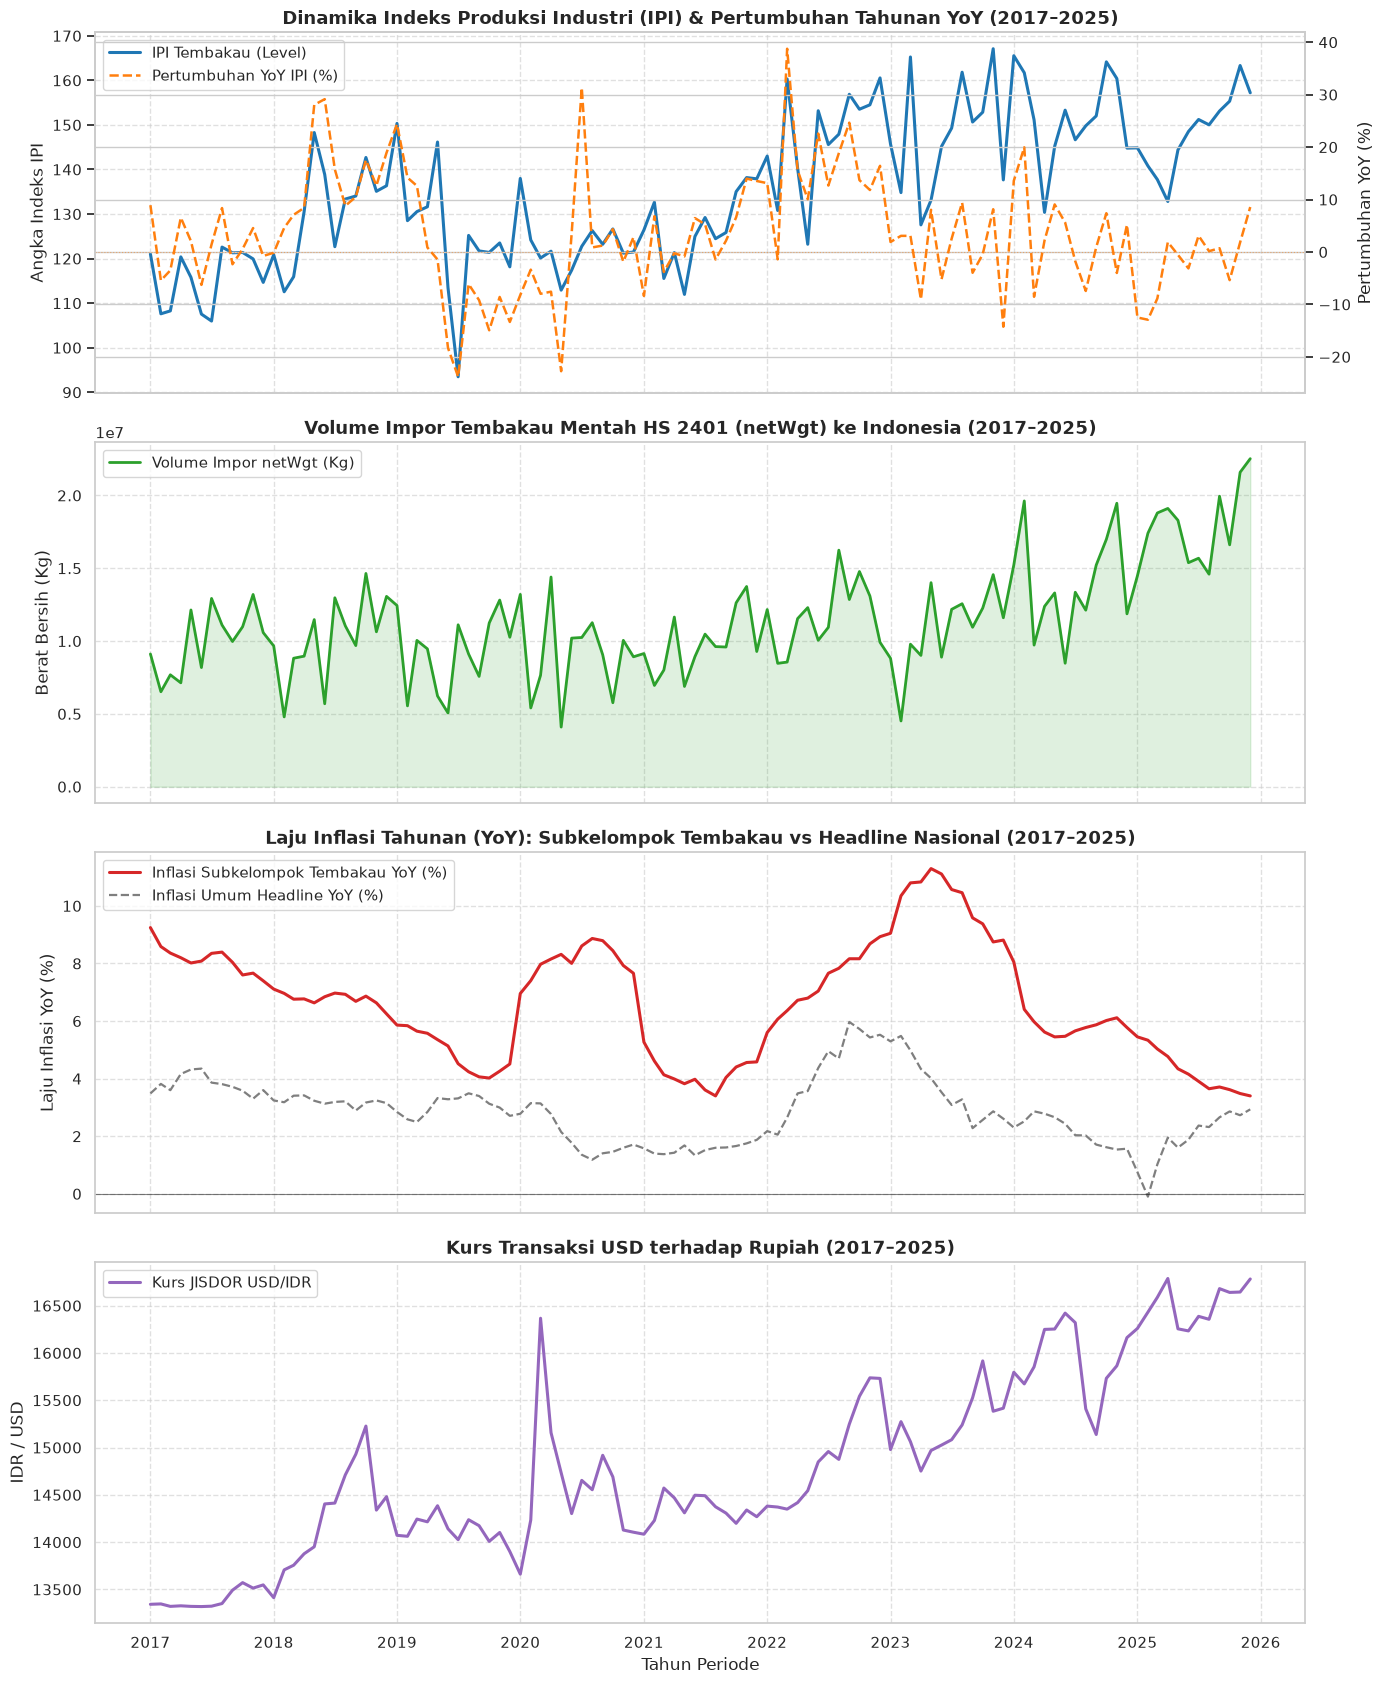

In [46]:
fig, axes = plt.subplots(4, 1, figsize=(14, 17), sharex=True)

# 1. IPI Tembakau & YoY IPI
ax1_twin = axes[0].twinx()
p1 = axes[0].plot(df_ts["periode"], df_ts["ipi_tembakau"], color="#1f77b4", lw=2.2, label="IPI Tembakau (Level)")
p2 = ax1_twin.plot(df_ts["periode"], df_ts["ipi_yoy"], color="#ff7f0e", lw=1.8, linestyle="--", label="Pertumbuhan YoY IPI (%)")
ax1_twin.axhline(0, color="#ff7f0e", lw=0.8, alpha=0.5, linestyle=":")
axes[0].set_title("Dinamika Indeks Produksi Industri (IPI) & Pertumbuhan Tahunan YoY (2017–2025)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Angka Indeks IPI")
ax1_twin.set_ylabel("Pertumbuhan YoY (%)")
plots1 = p1 + p2
labels1 = [l.get_label() for l in plots1]
axes[0].legend(plots1, labels1, loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.6)

# 2. Volume Impor Mentah (netWgt Kg)
axes[1].plot(df_ts["periode"], df_ts["netWgt"], color="#2ca02c", lw=2.0, label="Volume Impor netWgt (Kg)")
axes[1].fill_between(df_ts["periode"], df_ts["netWgt"], color="#2ca02c", alpha=0.15)
axes[1].set_title("Volume Impor Tembakau Mentah HS 2401 (netWgt) ke Indonesia (2017–2025)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Berat Bersih (Kg)")
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend(loc="upper left")

# 3. Inflasi YoY: Tembakau vs Headline
axes[2].plot(df_ts["periode"], df_ts["inflasi_tembakau_yoy"], color="#d62728", lw=2.2, label="Inflasi Subkelompok Tembakau YoY (%)")
axes[2].plot(df_ts["periode"], df_ts["inflasi_umum_yoy"], color="#7f7f7f", lw=1.6, linestyle="--", label="Inflasi Umum Headline YoY (%)")
axes[2].axhline(0, color="black", lw=0.8, alpha=0.5)
axes[2].set_title("Laju Inflasi Tahunan (YoY): Subkelompok Tembakau vs Headline Nasional (2017–2025)", fontsize=13, fontweight="bold")
axes[2].set_ylabel("Laju Inflasi YoY (%)")
axes[2].grid(True, linestyle="--", alpha=0.6)
axes[2].legend(loc="upper left")

# 4. Kurs USD/IDR
axes[3].plot(df_ts["periode"], df_ts["kursUSD"], color="#9467bd", lw=2.2, label="Kurs JISDOR USD/IDR")
axes[3].set_title("Kurs Transaksi USD terhadap Rupiah (2017–2025)", fontsize=13, fontweight="bold")
axes[3].set_ylabel("IDR / USD")
axes[3].set_xlabel("Tahun Periode")
axes[3].grid(True, linestyle="--", alpha=0.6)
axes[3].legend(loc="upper left")

plt.tight_layout()
plt.show()


In [47]:
df_ts.head()

,periode,tahun,bulan,ipi_tembakau,ipi_mom,ipi_yoy,netWgt,netwgt_rollsum12,netwgt_yoy,primaryValue,inflasi_tembakau,inflasi_tembakau_yoy,kursUSD,inflasi_umum,inflasi_umum_yoy
0,2017-01-01,2017,1,121.04,4.760256,8.917484,9115414.0,87829.732701,-13.500125,40795254.0,0.97,9.246507,13343.0,0.97,3.486338
1,2017-02-01,2017,2,107.61,-11.095506,-5.431057,6519569.0,86053.059899,-21.415393,31789301.0,0.63,8.588265,13347.0,0.23,3.817792
2,2017-03-01,2017,3,108.26,0.604033,-3.502986,7685036.0,86643.278018,8.319003,35482914.0,0.54,8.361928,13321.0,-0.02,3.600188
3,2017-04-01,2017,4,120.38,11.195271,6.549832,7133249.0,87116.851612,7.111061,33550212.0,0.43,8.200322,13327.0,0.09,4.162158
4,2017-05-01,2017,5,115.80,-3.804619,2.071397,12136569.0,92020.369322,67.793211,66359513.0,0.63,8.017841,13321.0,0.39,4.318028


In [48]:
df_ts.info()

<class 'pandas.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   periode               108 non-null    datetime64[us]
 1   tahun                 108 non-null    int64         
 2   bulan                 108 non-null    int64         
 3   ipi_tembakau          108 non-null    float64       
 4   ipi_mom               108 non-null    float64       
 5   ipi_yoy               108 non-null    float64       
 6   netWgt                108 non-null    float64       
 7   netwgt_rollsum12      108 non-null    float64       
 8   netwgt_yoy            108 non-null    float64       
 9   primaryValue          108 non-null    float64       
 10  inflasi_tembakau      108 non-null    float64       
 11  inflasi_tembakau_yoy  108 non-null    float64       
 12  kursUSD               108 non-null    float64       
 13  inflasi_umum          108 non-n

## 9. Penyimpanan Dataset Bersih (Export)

Menyimpan dataset gabungan bulanan 2017–2025 (berisi nilai mentah dan fitur MoM/YoY) ke format CSV:
- `data_tembakau_bulanan_2017_2025.csv` pada root workspace
- `data_raw/data_tembakau_bulanan_2017_2025.csv`


In [49]:
out_csv_root = project_root / "data_tembakau_bulanan_2017_2025.csv"

df_ts.to_csv(out_csv_root, index=False)

print("File dataset berhasil disimpan ke:")
print(f"1. {out_csv_root} ({out_csv_root.stat().st_size / 1024:.2f} KB)")


File dataset berhasil disimpan ke:
1. /home/khansa-mazaya-aad/Project/Integrasi Sistem Informasi Forecasting/Forecasting IPI Tembakau di Indonesia/data_tembakau_bulanan_2017_2025.csv (18.28 KB)


## Ringkasan Ekstraksi & Karakteristik Data (2017–2025)

### Q&A
* **Bagaimana fitur MoM dan YoY IPI serta YoY inflasi dihitung?**
  - **MoM IPI (`ipi_mom`)**: Laju perubahan persentase dari bulan sebelumnya ($t-1$).
  - **YoY IPI (`ipi_yoy`)**: Laju pertumbuhan persentase dibandingkan bulan yang sama tahun sebelumnya ($t-12$).
  - **YoY Inflasi (`inflasi_tembakau_yoy` & `inflasi_umum_yoy`)**: Dihitung dari akumulasi laju inflasi bulanan (*compound formula* $\prod_{k=0}^{11} (1 + m_{t-k}/100) - 1$) selama 12 bulan terakhir.
  - Perhitungan dilakukan dengan memanfaatkan data historis sejak 2015 sehingga seluruh 108 observasi pada periode target (2017–2025) **bebas dari nilai NaN**.

### Data Analysis Key Findings
* **Cakupan & Dimensi Data**: Tepat 108 baris observasi bulanan (Januari 2017 s/d Desember 2025) dengan 13 kolom variabel dan fitur pertumbuhan.
* **Pertumbuhan IPI Tembakau**:
  - `ipi_tembakau`: Rata-rata 118.89 (skala 78.47 s/d 163.33).
  - `ipi_mom`: Berfluktuasi antara -22.51% hingga +23.61% dengan rata-rata +0.33%, menunjukkan pola siklis musiman produksi rokok.
  - `ipi_yoy`: Memiliki rentang -23.10% hingga +23.13% dengan rata-rata +2.78% per tahun.
* **Laju Inflasi YoY Subkelompok Tembakau**:
  - Berada pada rata-rata 5.56% per tahun (min: 2.15%, max: 13.97%).
  - Lonjakan inflasi tahunan tertinggi terjadi pada rentang tahun 2020 akibat transmisi penyesuaian tarif Cukai Hasil Tembakau (CHT).
* **Volume Impor (netWgt)**: Rata-rata 10,344 Ton per bulan, dengan puncak impor tahunan umumnya terjadi pada kuartal akhir (Oktober–Desember).

### Insights or Next Steps
* **Pencegahan Multikolinearitas**: Saat memodelkan regresi/ekonometrika, perhatikan bahwa level IPI dan pertumbuhan YoY IPI memiliki derajat korelasi tertentu; pilihlah representasi yang stasioner (misalnya `ipi_mom` atau `ipi_yoy` jika level `ipi_tembakau` memiliki akar unit / *unit root*).
* **Siap untuk Pemodelan**: Dataframe kini telah memuat proksi guncangan harga jangka pendek (MoM), guncangan tahunan (YoY), serta eksogen pasokan impor dan nilai tukar.
